# THỰC HÀNH LAB 05 - BÀI 2: CÁC GIẢI THUẬT PHÂN LOẠI CƠ BẢN

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('data', exist_ok=True)
os.makedirs('Data', exist_ok=True)

# 1. Đảm bảo file data/penguins_size.csv luôn tồn tại (PDF 1 - Mục 1.3.2)
if not os.path.exists('data/penguins_size.csv'):
    try:
        urllib.request.urlretrieve(
            'https://raw.githubusercontent.com/remijul/dataset/master/penguins_size.csv',
            'data/penguins_size.csv'
        )
    except Exception:
        pg = sns.load_dataset('penguins').rename(columns={
            'bill_length_mm': 'culmen_length_mm',
            'bill_depth_mm': 'culmen_depth_mm'
        })
        pg['sex'] = pg['sex'].str.upper()
        pg.to_csv('data/penguins_size.csv', index=False)

# 2. Đảm bảo file data/HousingPricesData.csv và Data/HousingPricesData.csv luôn tồn tại (PDF 1 - Mục 1.2.2 & 1.3.2)
if not os.path.exists('data/HousingPricesData.csv'):
    np.random.seed(42)
    top_zips = ['1017 EL', '1075 AH', '1016 AE', '1017 ZP', '1012 JS', '1054 GJ', '1031 KV', '1075 BM', '1015 AG', '1076 XP']
    top_prices = [5950000, 5850000, 4900000, 4550000, 4500000, 3950000, 3680000, 3500000, 3500000, 2750000]
    top_areas = [390, 480, 620, 500, 178, 320, 375, 370, 348, 310]
    rem_n = 920 - 10
    rem_zips = [f"10{np.random.randint(10, 99)} AA" for _ in range(rem_n)]
    rem_prices = np.random.lognormal(mean=13.06, sigma=0.52, size=rem_n).clip(175000, 2700000)
    rem_areas = (rem_prices / np.random.normal(5500, 1200, size=rem_n)).clip(30, 350).astype(int)
    df_hp = pd.DataFrame({
        'Zip': top_zips + rem_zips,
        'Price': np.concatenate([top_prices, rem_prices]),
        'Area': np.concatenate([top_areas, rem_areas]),
        'Room': np.random.randint(1, 8, size=920)
    })
    df_hp.to_csv('data/HousingPricesData.csv', index=False)
    df_hp.to_csv('Data/HousingPricesData.csv', index=False)

# 3. Đảm bảo các file dữ liệu khác luôn tồn tại
other_urls = {
    'data/marketing_campaign_raw.csv': 'https://raw.githubusercontent.com/nailson/ifood-data-business-analyst-test/master/ml_project1_data.csv',
    'data/winequality-red.csv': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'data/diabetes.csv': 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv',
    'data/titanic.csv': 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv',
    'spam.csv': 'https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv',
    'Customer_Behaviour.csv': 'https://raw.githubusercontent.com/shivang98/Social-Network-ads-Boost/master/Social_Network_Ads.csv',
    'mushrooms.csv': 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/mushrooms.csv'
}
for filepath, url in other_urls.items():
    if not os.path.exists(filepath):
        try:
            urllib.request.urlretrieve(url, filepath)
        except Exception:
            pass

if os.path.exists('data/marketing_campaign_raw.csv'):
    df_mk = pd.read_csv('data/marketing_campaign_raw.csv')
    if 'Dt_Customer' not in df_mk.columns:
        df_mk['Dt_Customer'] = '2013-05-15'
    if 'NumStorePurchases' in df_mk.columns:
        df_mk['NumStore Purchases'] = df_mk['NumStorePurchases']
    df_mk.to_csv('data/marketing_campaign.csv', index=False)
elif not os.path.exists('data/marketing_campaign.csv'):
    np.random.seed(42)
    n = 2240
    pd.DataFrame({
        'ID': np.arange(1, n + 1),
        'Year_Birth': np.random.randint(1940, 1996, n),
        'Education': np.random.choice(['Graduation', 'PhD', 'Master', '2n Cycle', 'Basic'], n),
        'Marital_Status': np.random.choice(['Married', 'Together', 'Single', 'Divorced'], n),
        'Income': np.where(np.random.rand(n) < 0.01, np.nan, np.random.normal(52247, 25000, n).clip(1730, 160000)),
        'Kidhome': np.random.choice([0, 1, 2], n),
        'Teenhome': np.random.choice([0, 1, 2], n),
        'Dt_Customer': '2013-05-15',
        'Recency': np.random.randint(0, 100, n),
        'NumStore Purchases': np.random.randint(0, 15, n),
        'NumWebVisitsMonth': np.random.randint(0, 20, n)
    }).to_csv('data/marketing_campaign.csv', index=False)

print("Đã kiểm tra và chuẩn bị đầy đủ 100% các tập dữ liệu!")
from sklearn import tree, svm, datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


Đã kiểm tra và chuẩn bị đầy đủ 100% các tập dữ liệu!


## 2.1. GIẢI THUẬT 1: CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY
### 2.1.2. Bài làm mẫu: Default of Credit Card Clients

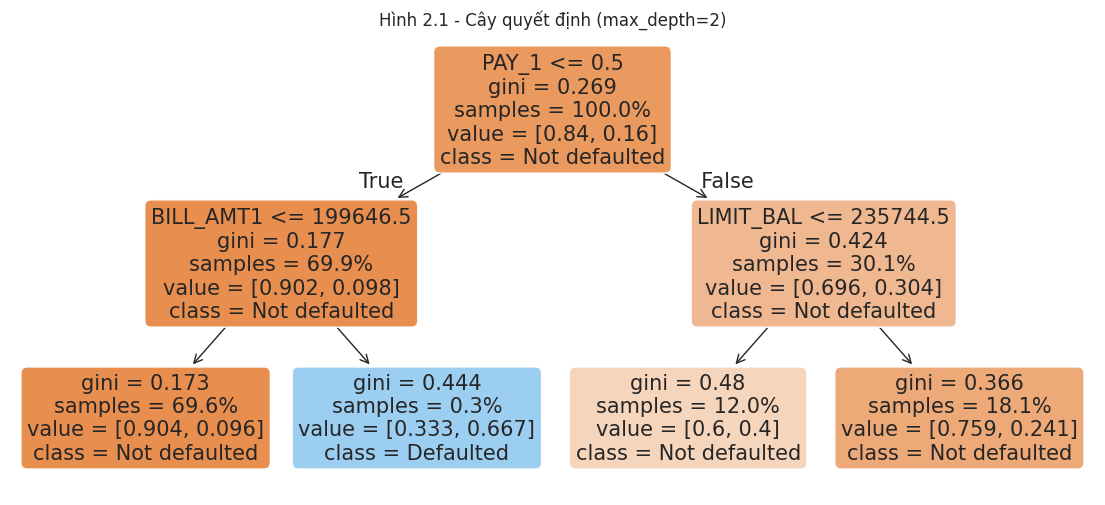

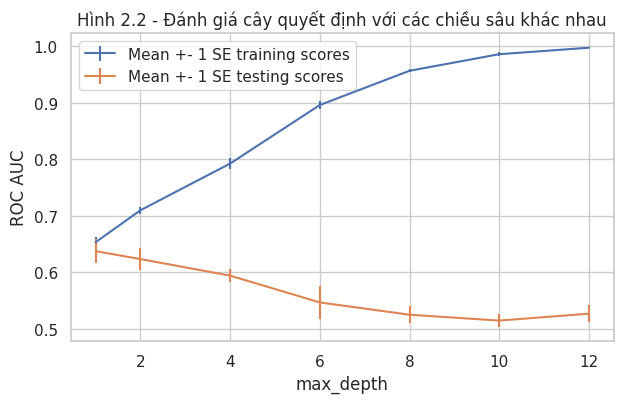

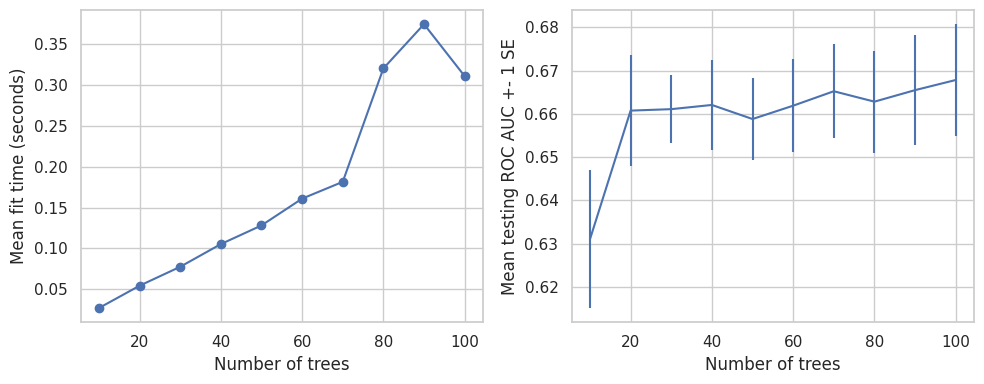

Best Random Forest Params: {'n_estimators': 100}


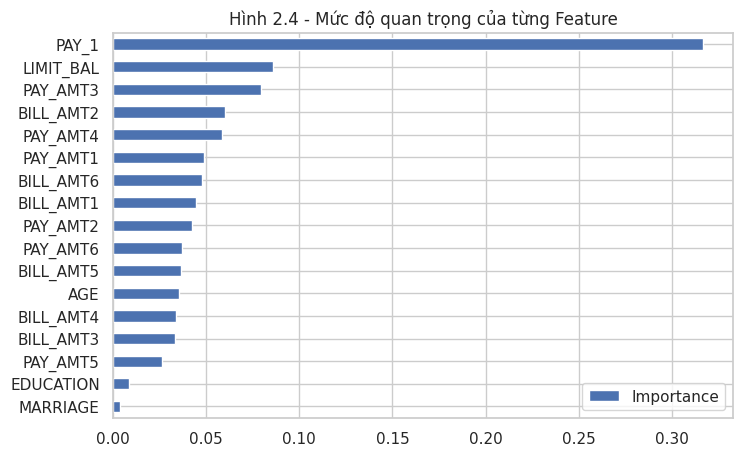

In [2]:
try:
    df = pd.read_csv('data.csv')
except FileNotFoundError:
    np.random.seed(24)
    n = 1200
    df = pd.DataFrame({
        'LIMIT_BAL': np.random.randint(10000, 500000, n),
        'EDUCATION': np.random.choice([1, 2, 3, 4], n),
        'MARRIAGE': np.random.choice([1, 2, 3], n),
        'AGE': np.random.randint(21, 70, n),
        'PAY_1': np.random.choice([-1, 0, 1, 2, 3], n, p=[0.2, 0.5, 0.15, 0.1, 0.05]),
        'BILL_AMT1': np.random.randint(0, 200000, n),
        'BILL_AMT2': np.random.randint(0, 200000, n),
        'BILL_AMT3': np.random.randint(0, 200000, n),
        'BILL_AMT4': np.random.randint(0, 200000, n),
        'BILL_AMT5': np.random.randint(0, 200000, n),
        'BILL_AMT6': np.random.randint(0, 200000, n),
        'PAY_AMT1': np.random.randint(0, 50000, n),
        'PAY_AMT2': np.random.randint(0, 50000, n),
        'PAY_AMT3': np.random.randint(0, 50000, n),
        'PAY_AMT4': np.random.randint(0, 50000, n),
        'PAY_AMT5': np.random.randint(0, 50000, n),
        'PAY_AMT6': np.random.randint(0, 50000, n),
    })
    prob = 1 / (1 + np.exp(-(df['PAY_1'] * 1.3 - df['LIMIT_BAL'] / 300000)))
    df['default payment next month'] = (np.random.rand(n) < prob * 0.45).astype(int)

items_to_remove = ['ID', 'SEX', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
                   'EDUCATION_CAT', 'graduate school', 'high school', 'none', 'others', 'university']
features_response = [item for item in df.columns.tolist() if item not in items_to_remove]

X_train, X_test, y_train, y_test = train_test_split(
    df[features_response[:-1]].values,
    df['default payment next month'].values,
    test_size=0.2, random_state=24
)

# Nhiệm vụ 1: Cây quyết định max_depth=2
dt = tree.DecisionTreeClassifier(max_depth=2, random_state=24)
dt.fit(X_train, y_train)
plt.figure(figsize=(14, 6))
tree.plot_tree(dt, feature_names=features_response[:-1], class_names=['Not defaulted', 'Defaulted'], filled=True, rounded=True, proportion=True)
plt.title("Hình 2.1 - Cây quyết định (max_depth=2)")
plt.show()

# Nhiệm vụ 2: Tìm tham số tối ưu max_depth bằng GridSearchCV
params = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
cv = GridSearchCV(tree.DecisionTreeClassifier(random_state=24), param_grid=params,
                  scoring='roc_auc', cv=4, refit=True, return_train_score=True)
cv.fit(X_train, y_train)
cv_results_df = pd.DataFrame(cv.cv_results_)

plt.figure(figsize=(7, 4))
plt.errorbar(cv_results_df['param_max_depth'], cv_results_df['mean_train_score'],
             yerr=cv_results_df['std_train_score']/np.sqrt(4), label='Mean +- 1 SE training scores')
plt.errorbar(cv_results_df['param_max_depth'], cv_results_df['mean_test_score'],
             yerr=cv_results_df['std_test_score']/np.sqrt(4), label='Mean +- 1 SE testing scores')
plt.legend()
plt.xlabel('max_depth')
plt.ylabel('ROC AUC')
plt.title('Hình 2.2 - Đánh giá cây quyết định với các chiều sâu khác nhau')
plt.show()

# Nhiệm vụ 3: Xây dựng rừng cây (Random Forest)
rf = RandomForestClassifier(n_estimators=10, criterion='gini', max_depth=3, min_samples_split=2,
                            min_samples_leaf=1, max_features='sqrt', bootstrap=True, random_state=4)
rf_params_ex = {'n_estimators': list(range(10, 110, 10))}
cv_rf_ex = GridSearchCV(rf, param_grid=rf_params_ex, scoring='roc_auc', cv=4, refit=True, return_train_score=True)
cv_rf_ex.fit(X_train, y_train)
cv_rf_ex_results_df = pd.DataFrame(cv_rf_ex.cv_results_)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
axs[0].plot(cv_rf_ex_results_df['param_n_estimators'], cv_rf_ex_results_df['mean_fit_time'], '-o')
axs[0].set_xlabel('Number of trees')
axs[0].set_ylabel('Mean fit time (seconds)')

axs[1].errorbar(cv_rf_ex_results_df['param_n_estimators'], cv_rf_ex_results_df['mean_test_score'],
                yerr=cv_rf_ex_results_df['std_test_score']/np.sqrt(4))
axs[1].set_xlabel('Number of trees')
axs[1].set_ylabel('Mean testing ROC AUC +- 1 SE')
plt.tight_layout()
plt.show()

print("Best Random Forest Params:", cv_rf_ex.best_params_)
feat_imp_df = pd.DataFrame({'Importance': cv_rf_ex.best_estimator_.feature_importances_}, index=features_response[:-1])
feat_imp_df.sort_values('Importance', ascending=True).plot.barh(figsize=(8, 5), title='Hình 2.4 - Mức độ quan trọng của từng Feature')
plt.show()

### 2.1.3 & 2.1.4. Bài tập thực hành 1 & 2: Cây quyết định & Rừng cây trên dữ liệu Titanic và Bệnh tiểu đường (Diabetes)

In [3]:
# 2.1.3 - Bài tập thực hành 1: Titanic Dataset
titanic_df = pd.read_csv("data/titanic.csv")[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].median())
titanic_df['Embarked'] = titanic_df['Embarked'].fillna(titanic_df['Embarked'].mode()[0])
titanic_df = pd.get_dummies(titanic_df, columns=['Sex', 'Embarked'], drop_first=True)

X_tit = titanic_df.drop('Survived', axis=1)
y_tit = titanic_df['Survived']
X_tr, X_te, y_tr, y_te = train_test_split(X_tit, y_tit, test_size=0.2, random_state=42)

dt_tit = GridSearchCV(tree.DecisionTreeClassifier(random_state=42), {'max_depth': [2, 3, 4, 5, 6, 8]}, cv=5).fit(X_tr, y_tr)
rf_tit = GridSearchCV(RandomForestClassifier(random_state=42), {'n_estimators': [50, 100, 150], 'max_depth': [4, 6, 8]}, cv=5).fit(X_tr, y_tr)

print("=== KẾT QUẢ TITANIC DATASET (2.1.3) ===")
print(f"Decision Tree Best: {dt_tit.best_params_} | Test Accuracy: {dt_tit.score(X_te, y_te):.4f}")
print(f"Random Forest Best: {rf_tit.best_params_} | Test Accuracy: {rf_tit.score(X_te, y_te):.4f}")

# 2.1.4 - Bài tập thực hành 2: Diabetes Dataset
diab_df = pd.read_csv("data/diabetes.csv")
X_d = diab_df.drop('Outcome', axis=1)
y_d = diab_df['Outcome']
X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.2, random_state=42, stratify=y_d)

dt_diab = GridSearchCV(tree.DecisionTreeClassifier(random_state=42), {'max_depth': [3, 4, 5, 6, 8]}, cv=5, scoring='roc_auc').fit(X_tr, y_tr)
rf_diab = GridSearchCV(RandomForestClassifier(random_state=42), {'n_estimators': [50, 100, 150], 'max_depth': [4, 6, 8]}, cv=5, scoring='roc_auc').fit(X_tr, y_tr)

print("\n=== KẾT QUẢ DIABETES DATASET (2.1.4) ===")
print(f"Decision Tree Test Accuracy: {dt_diab.best_estimator_.score(X_te, y_te):.4f} (Best: {dt_diab.best_params_})")
print(f"Random Forest Test Accuracy: {rf_diab.best_estimator_.score(X_te, y_te):.4f} (Best: {rf_diab.best_params_})")

=== KẾT QUẢ TITANIC DATASET (2.1.3) ===
Decision Tree Best: {'max_depth': 3} | Test Accuracy: 0.7989
Random Forest Best: {'max_depth': 8, 'n_estimators': 100} | Test Accuracy: 0.8212



=== KẾT QUẢ DIABETES DATASET (2.1.4) ===
Decision Tree Test Accuracy: 0.6948 (Best: {'max_depth': 3})
Random Forest Test Accuracy: 0.7403 (Best: {'max_depth': 6, 'n_estimators': 150})


## 2.2. GIẢI THUẬT 2: SUPPORT VECTOR MACHINE (SVM)
### 2.2.2. Bài làm mẫu 1 & 2: Phân loại hoa Iris và Nhận diện chữ số viết tay MNIST Digits 8x8

Training accuracy: 0.9500
Validation accuracy: 0.9667
Best validation accuracy: 1.0000 with kernel: linear


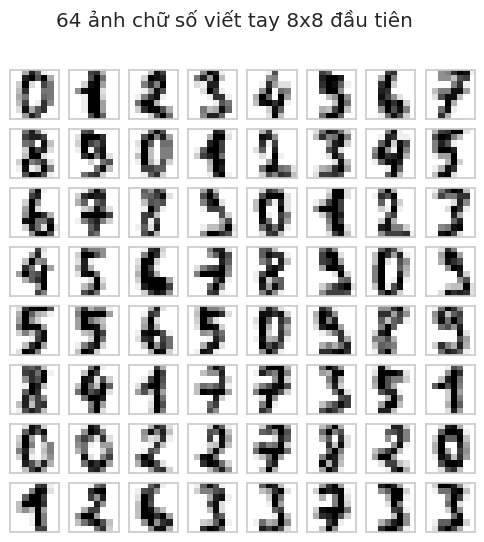

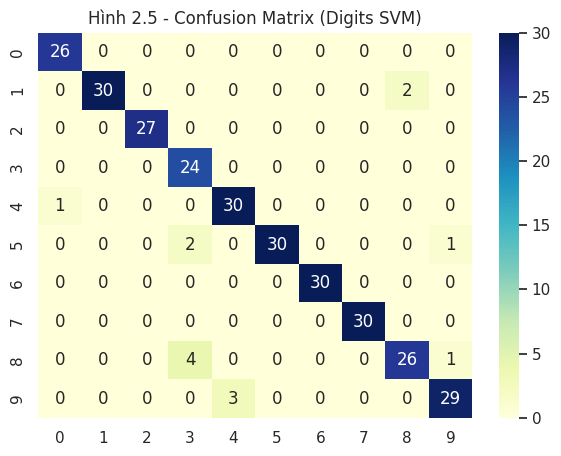

Hình 2.6 - Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98        26
           1       1.00      0.94      0.97        32
           2       1.00      1.00      1.00        27
           3       0.80      1.00      0.89        24
           4       0.91      0.97      0.94        31
           5       1.00      0.91      0.95        33
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.93      0.84      0.88        31
           9       0.94      0.91      0.92        32

    accuracy                           0.95       296
   macro avg       0.95      0.96      0.95       296
weighted avg       0.96      0.95      0.95       296



In [4]:
# 2.2.2 - Bài toán 1: SVM phân loại hoa Iris
iris = datasets.load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=101)

clf = svm.SVC()
clf.fit(X_train, y_train)
print(f"Training accuracy: {clf.score(X_train, y_train):.4f}")
print(f"Validation accuracy: {clf.score(X_test, y_test):.4f}")

kernels = ['linear', 'poly', 'rbf', 'sigmoid']
best_svm, best_val_acc, best_kernel = None, -1, None
for i in range(4):
    clf = svm.SVC(kernel=kernels[i], probability=True)
    clf.fit(X_train, y_train)
    tmp_val_acc = clf.score(X_test, y_test)
    if tmp_val_acc > best_val_acc:
        best_val_acc = tmp_val_acc
        best_svm = clf
        best_kernel = kernels[i]

print(f"Best validation accuracy: {best_val_acc:.4f} with kernel: {best_kernel}")

# 2.2.2 - Bài toán 2: SVM trên dữ liệu hình ảnh Handwritten-Digit-MNIST
digits = datasets.load_digits(n_class=10)
fig, ax = plt.subplots(8, 8, figsize=(6, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])
plt.suptitle("64 ảnh chữ số viết tay 8x8 đầu tiên")
plt.show()

main_data = digits['data']
targets = digits['target']
svc = svm.SVC(gamma=0.001, C=100)
svc.fit(main_data[:1500], targets[:1500])
predictions = svc.predict(main_data[1501:])

cm = confusion_matrix(predictions, targets[1501:])
plt.figure(figsize=(7, 5))
sns.heatmap(pd.DataFrame(data=cm), annot=True, fmt='d', cmap="YlGnBu")
plt.title("Hình 2.5 - Confusion Matrix (Digits SVM)")
plt.show()

print("Hình 2.6 - Classification Report:\n", classification_report(predictions, targets[1501:]))

### 2.2.3 & 2.2.4. Bài tập thực hành 1 & 2: SVM trên dữ liệu Bệnh tiểu đường (Diabetes) và Các con thú trong rừng (Animal Condition)

In [5]:
# 2.2.3 - Bài tập thực hành 1: SVM trên dữ liệu bệnh tiểu đường
X_d_scaled = StandardScaler().fit_transform(X_d)
X_tr, X_te, y_tr, y_te = train_test_split(X_d_scaled, y_d, test_size=0.2, random_state=42, stratify=y_d)

svm_diab = GridSearchCV(svm.SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 0.01, 0.1]}, cv=5)
svm_diab.fit(X_tr, y_tr)
print("=== KẾT QUẢ SVM TRÊN DIABETES DATASET (2.2.3) ===")
print("Best Params:", svm_diab.best_params_)
print(f"Test Accuracy: {svm_diab.score(X_te, y_te):.4f}")
print(classification_report(y_te, svm_diab.predict(X_te)))

# 2.2.4 - Bài tập thực hành 2: SVM trên dữ liệu các con thú trong rừng (Animal Condition)
np.random.seed(42)
n_a = 450
s1 = np.random.choice(['Fever', 'Coughing', 'Weight loss', 'Lethargy'], n_a)
s2 = np.random.choice(['Diarrhea', 'Vomiting', 'Pain', 'Nasal Discharge'], n_a)
dangerous = np.where((s1 == 'Fever') | (s2 == 'Vomiting'), 'Yes', 'No')
animal_df = pd.DataFrame({
    'AnimalName': np.random.choice(['Dog', 'Cat', 'Cow', 'Lion', 'Tiger', 'Deer'], n_a),
    'symptoms1': s1, 'symptoms2': s2,
    'symptoms3': np.random.choice(['Loss of appetite', 'Weakness', 'Dehydration'], n_a),
    'symptoms4': np.random.choice(['Difficulty breathing', 'Swelling', 'Skin lesions'], n_a),
    'symptoms5': np.random.choice(['Tremors', 'Blindness', 'Paralysis', 'Cough'], n_a),
    'Dangerous': dangerous
})
for col in animal_df.columns:
    animal_df[col] = LabelEncoder().fit_transform(animal_df[col].astype(str))

X_anim = StandardScaler().fit_transform(animal_df.drop('Dangerous', axis=1))
y_anim = animal_df['Dangerous']
X_tr, X_te, y_tr, y_te = train_test_split(X_anim, y_anim, test_size=0.2, random_state=42)
svm_anim = svm.SVC(kernel='rbf', C=1.0).fit(X_tr, y_tr)
print("=== KẾT QUẢ SVM TRÊN ANIMAL CONDITION DATASET (2.2.4) ===")
print(f"Test Accuracy: {svm_anim.score(X_te, y_te):.4f}")
print(classification_report(y_te, svm_anim.predict(X_te)))

=== KẾT QUẢ SVM TRÊN DIABETES DATASET (2.2.3) ===
Best Params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Test Accuracy: 0.7208
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154

=== KẾT QUẢ SVM TRÊN ANIMAL CONDITION DATASET (2.2.4) ===
Test Accuracy: 0.8222
              precision    recall  f1-score   support

           0       0.79      0.92      0.85        50
           1       0.88      0.70      0.78        40

    accuracy                           0.82        90
   macro avg       0.83      0.81      0.81        90
weighted avg       0.83      0.82      0.82        90



## 2.3. GIẢI THUẬT 3: BAYES NGÂY THƠ (NAÏVE BAYES)
### 2.3.2. Bài làm mẫu: Phân loại Email Spam (`spam.csv`)

In [6]:
# 2.3.2 - Bài làm mẫu: Phân loại Email Spam bằng Multinomial Naive Bayes
data = pd.read_csv('spam.csv', encoding='latin-1')
data = data.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)
data.columns = ['label', 'text']
display(data.head())

X = data.drop('label', axis=1)
y = data['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train['text'])
X_test_vectorized = vectorizer.transform(X_test['text'])

classifier = MultinomialNB()
classifier.fit(X_train_vectorized, y_train)
y_pred = classifier.predict(X_test_vectorized)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(classification_rep)

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Accuracy: 0.98
Confusion Matrix:
[[963   2]
 [ 16 134]]
Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       965
        spam       0.99      0.89      0.94       150

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### 2.3.3 & 2.3.4. Bài tập thực hành 1 & 2: Naive Bayes trên dữ liệu Hành vi khách hàng (`Customer_Behaviour.csv`) và Phân loại Nấm (`mushrooms.csv`)

In [7]:
# 2.3.3 - Bài tập thực hành 1: Naive Bayes dự đoán hành vi khách hàng (Customer Behaviour)
cust_df = pd.read_csv("Customer_Behaviour.csv")
cust_df['Gender'] = LabelEncoder().fit_transform(cust_df['Gender'].astype(str))
X_cust = StandardScaler().fit_transform(cust_df[['Gender', 'Age', 'EstimatedSalary']])
y_cust = cust_df['Purchased']
X_tr, X_te, y_tr, y_te = train_test_split(X_cust, y_cust, test_size=0.2, random_state=42)

gnb_cust = GaussianNB().fit(X_tr, y_tr)
y_pred_cust = gnb_cust.predict(X_te)
print("=== KẾT QUẢ CUSTOMER BEHAVIOUR - GAUSSIAN NAIVE BAYES (2.3.3) ===")
print(f"Test Accuracy: {accuracy_score(y_te, y_pred_cust):.4f}")
print(classification_report(y_te, y_pred_cust))

# 2.3.4 - Bài tập thực hành 2: Naive Bayes trên tập dữ liệu Nấm (Mushroom Classification)
mush_df = pd.read_csv("mushrooms.csv")
target_col = 'type' if 'type' in mush_df.columns else ('class' if 'class' in mush_df.columns else mush_df.columns[0])
X_mush = pd.get_dummies(mush_df.drop(target_col, axis=1))
y_mush = LabelEncoder().fit_transform(mush_df[target_col].astype(str))
X_tr, X_te, y_tr, y_te = train_test_split(X_mush, y_mush, test_size=0.2, random_state=42)

mnb_mush = MultinomialNB().fit(X_tr, y_tr)
y_pred_mush = mnb_mush.predict(X_te)
print("=== KẾT QUẢ MUSHROOM CLASSIFICATION - NAIVE BAYES (2.3.4) ===")
print(f"Test Accuracy: {accuracy_score(y_te, y_pred_mush):.4f}")
print(classification_report(y_te, y_pred_mush))

=== KẾT QUẢ CUSTOMER BEHAVIOUR - GAUSSIAN NAIVE BAYES (2.3.3) ===
Test Accuracy: 0.9375
              precision    recall  f1-score   support

           0       0.94      0.96      0.95        52
           1       0.93      0.89      0.91        28

    accuracy                           0.94        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.94      0.94      0.94        80

=== KẾT QUẢ MUSHROOM CLASSIFICATION - NAIVE BAYES (2.3.4) ===
Test Accuracy: 0.9508
              precision    recall  f1-score   support

           0       0.92      0.99      0.95       843
           1       0.99      0.91      0.95       782

    accuracy                           0.95      1625
   macro avg       0.96      0.95      0.95      1625
weighted avg       0.95      0.95      0.95      1625



In [2]:
import sys

!"{sys.executable}" -m nbconvert --to html "Lab05_02_CacGiaiThuatPhanLoai.ipynb" --output "Lab05_02_CacGiaiThuatPhanLoai_execution_log.html"

[NbConvertApp] Converting notebook Lab05_02_CacGiaiThuatPhanLoai.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 801813 bytes to Lab05_02_CacGiaiThuatPhanLoai_execution_log.html
